In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [6]:
df=pd.read_csv("fruit_types.csv")

In [7]:
df.head()

,weight_g,size_cm,colour_score,fruit
0,180,7.6,0.87,Apple
1,180,7.3,0.58,Orange
2,214,8.7,0.51,Orange
3,100,17.9,0.36,Banana
4,103,17.2,0.30,Banana


In [8]:
print(df.shape)
print(df.isnull().sum())
print("Duplicate Rows:",df.duplicated().sum())

(92, 4)
weight_g        0
size_cm         2
colour_score    0
fruit           0
dtype: int64
Duplicate Rows: 2


In [9]:
print(df["fruit"].value_counts())

fruit
Apple      30
Orange     29
Banana     29
aple        2
Banana      1
orange      1
Name: count, dtype: int64


In [10]:
df.describe().round(1)

,weight_g,size_cm,colour_score
count,92.0,90.0,92.0
mean,171.4,11.3,0.5
std,174.7,5.0,0.2
min,92.0,6.3,0.2
25%,134.8,7.7,0.3
50%,154.5,8.3,0.6
75%,171.2,17.0,0.7
max,1810.0,21.8,0.9


In [11]:
df=df.drop_duplicates()
print(df.shape)

(90, 4)


In [12]:
#clean the fruits name 
df["fruit"]=df["fruit"].str.strip()
df["fruit"]=df["fruit"].str.capitalize()
df["fruit"]=df["fruit"].replace("Aple","Apple")
print(df["fruit"].value_counts())

fruit
Apple     30
Orange    30
Banana    30
Name: count, dtype: int64


In [13]:
print(df[df["weight_g"]>1000]) 

   weight_g  size_cm  colour_score   fruit
9      1810      7.5          0.62  Orange


In [14]:
df.loc[df["weight_g"]>1000,"weight_g"]=None
print(df["weight_g"].max())

223.0


In [15]:
Weight_median=df["weight_g"].median()
Size_median=df["size_cm"].median()
df["weight_g"]=df["weight_g"].fillna(Weight_median)
df["size_cm"]=df["size_cm"].fillna(Size_median)
print("Median weight:",Weight_median)
print("Median size:",Size_median)
print("Missing Values left:",df.isnull().sum().sum())

Median weight: 154.0
Median size: 8.3
Missing Values left: 0


In [16]:
df.groupby("fruit").mean().round(2)

,weight_g,size_cm,colour_score
fruit,,,
Apple,159.70,7.73,0.74
Banana,127.33,18.05,0.26
Orange,172.60,8.04,0.56


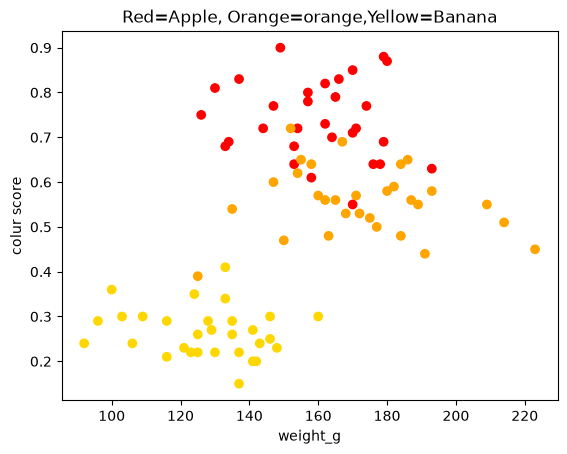

In [17]:
colours=df["fruit"].map({"Apple":"red","Orange":"orange","Banana":"gold"})
plt.scatter(df["weight_g"],df["colour_score"],c=colours)
plt.xlabel("weight_g")
plt.ylabel("colur score")
plt.title("Red=Apple, Orange=orange,Yellow=Banana")
plt.show()

In [18]:
X=df.drop(columns="fruit")
y=df["fruit"]
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

Scaler=StandardScaler()
x_train_scaled= Scaler.fit_transform(x_train)
x_test_scaled= Scaler.transform(x_test)
print(x_train_scaled.shape)
print(x_test_scaled.shape)
print(y_test.value_counts().to_dict())

(72, 3)
(18, 3)
{'Orange': 6, 'Apple': 6, 'Banana': 6}


In [19]:
#Make the model 
model = KNeighborsClassifier(n_neighbors=5)
model.fit(x_train_scaled,y_train)
print("Model is trained")

Model is trained


In [20]:
y_pred=model.predict(x_test_scaled)
train_pred=model.predict(x_train_scaled)
print("Train Accuracy:",round(accuracy_score(y_train,train_pred),3))
print("Test Accuracy:",round(accuracy_score(y_test,y_pred),3))

Train Accuracy: 0.931
Test Accuracy: 0.889


In [21]:
cm = confusion_matrix(y_test,y_pred)
cm_table=pd.DataFrame(cm,index=model.classes_,columns=model.classes_)
print(cm_table)

        Apple  Banana  Orange
Apple       5       0       1
Banana      0       6       0
Orange      1       0       5


In [22]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

       Apple       0.83      0.83      0.83         6
      Banana       1.00      1.00      1.00         6
      Orange       0.83      0.83      0.83         6

    accuracy                           0.89        18
   macro avg       0.89      0.89      0.89        18
weighted avg       0.89      0.89      0.89        18



In [23]:
new_fruit= pd.DataFrame({
    "weight_g":[165],
    "size_cm":[7.8],
    "colour_score":[0.68]
})

new_scaled=Scaler.transform(new_fruit)

print("Answer:", model.predict(new_scaled)[0])
print("Classes:",model.classes_)
print("Votes:", model.predict_proba(new_scaled)[0])

Answer: Apple
Classes: ['Apple' 'Banana' 'Orange']
Votes: [0.6 0.  0.4]
